# Chapitre 12 - Cours 1 : le classifieur à vaste marge

Ce premier notebook du chapitre 12 (sections 12.1 à 12.2 du livre) construit pas à pas le
**classifieur à vecteurs de support** (*support vector classifier*) :

1. hyperplans séparateurs et notion de **marge** ;
2. les outils d'optimisation sous contraintes nécessaires : **Lagrangien**, **conditions de
   Karush–Kuhn–Tucker (KKT)**, **dualité** - introduits au niveau Licence ;
3. le cas **séparable** (marge « dure ») ;
4. le cas **non séparable** (marge « souple », variables d'écart, paramètre de coût $C$) ;
5. la résolution numérique du problème dual (algorithme **SMO**) ;
6. l'exemple « mixture » du livre (figure 12.2).

Les noyaux (SVM non linéaires), la perte charnière et la régression sont l'objet du cours 2 ;
les discriminants flexibles (FDA, PDA, MDA) du cours 3.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch12_svm import (SVMClassifier, smo_solve, qp_interior_point, simulate_mixture,
                          mixture_bayes_prob, plot_mixture_boundary)
set_style()

## 1. Hyperplans et distance signée

On dispose de $N$ observations $(x_i, y_i)$ avec $x_i \in \mathbb{R}^p$ et une étiquette
$y_i \in \{-1, +1\}$. Un **hyperplan** de $\mathbb{R}^p$ est un ensemble de la forme

$$\{x : f(x) = x^T\beta + \beta_0 = 0\}, \qquad \beta \in \mathbb{R}^p\setminus\{0\},\ \beta_0\in\mathbb{R}$$

(éq. (12.1) du livre). La règle de classement associée est $G(x) = \mathrm{sign}[f(x)]$
(éq. (12.2)).

**Propriété (distance signée).** Si $\|\beta\| = 1$, la distance euclidienne de $x$ à
l'hyperplan vaut $|f(x)|$, et le signe de $f(x)$ indique de quel côté se trouve $x$.

*Démonstration.* Soit $x_0$ un point de l'hyperplan : $x_0^T\beta = -\beta_0$. Le vecteur
$\beta$ est orthogonal à l'hyperplan (pour deux points $x_0, x_0'$ de l'hyperplan,
$(x_0 - x_0')^T\beta = 0$). La distance de $x$ à l'hyperplan est donc la longueur de la
projection de $x - x_0$ sur la direction unitaire $\beta/\|\beta\|$ :

$$d(x) = \frac{(x - x_0)^T\beta}{\|\beta\|} = \frac{x^T\beta + \beta_0}{\|\beta\|} = \frac{f(x)}{\|\beta\|}.$$

Avec $\|\beta\| = 1$ on obtient $d(x) = f(x)$. $\square$

> **À retenir.** Pour $\beta$ quelconque, $f(x)/\|\beta\|$ est la distance signée de $x$ à
> l'hyperplan. Un point est bien classé si et seulement si $y_i f(x_i) > 0$.

Construisons un petit jeu de données **séparable** en dimension 2 pour illustrer. Une infinité
d'hyperplans séparent parfaitement les deux classes : lequel choisir ?

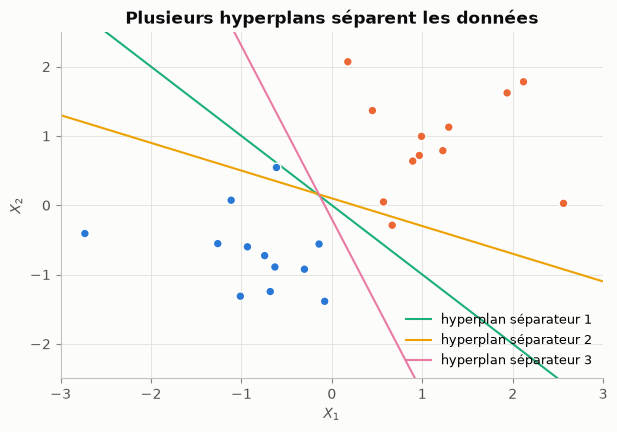

In [2]:
rng = np.random.RandomState(0)
n = 12
Xs = np.vstack([rng.randn(n, 2) * 0.6 + [-1.2, -0.8], rng.randn(n, 2) * 0.6 + [1.2, 0.9]])
ys = np.r_[-np.ones(n), np.ones(n)]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(Xs[:, 0], Xs[:, 1], c=(ys > 0), cmap=TWO_CLASS, s=40, edgecolor="white", zorder=3)
t = np.linspace(-3, 3, 10)
for k, (a, b0) in enumerate([(-1.0, 0.0), (-0.4, 0.1), (-2.5, -0.2)]):
    ax.plot(t, a * t + b0, color=COLORS[2 + k], lw=1.5, label="hyperplan séparateur %d" % (k + 1))
ax.set_xlim(-3, 3); ax.set_ylim(-2.5, 2.5)
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$")
ax.set_title("Plusieurs hyperplans séparent les données")
ax.legend(loc="lower right")
plt.show()

## 2. Le problème de la marge maximale

Si les classes sont séparables, il existe $f$ affine avec $y_i f(x_i) > 0$ pour tout $i$.
L'idée est de choisir l'hyperplan qui maximise la **marge** $M$, c'est-à-dire la distance
minimale entre l'hyperplan et les points d'apprentissage (éq. (12.3) du livre) :

$$\max_{\beta, \beta_0,\ \|\beta\| = 1} M \quad \text{sous les contraintes} \quad y_i(x_i^T\beta + \beta_0) \ge M,\quad i = 1, \dots, N.$$

La bande de part et d'autre de l'hyperplan a une largeur totale $2M$.

**Reformulation (éq. (12.4)).** La contrainte $\|\beta\| = 1$ est gênante (elle n'est pas
convexe). On s'en débarrasse en remarquant que :

* pour $\beta$ quelconque, la contrainte $y_i(x_i^T\beta + \beta_0)/\|\beta\| \ge M$
  exprime la même chose (distance signée) ;
* le couple $(\beta, \beta_0)$ n'est défini qu'à un facteur positif près : on peut donc
  **choisir l'échelle** $\|\beta\| = 1/M$.

Les contraintes deviennent $y_i(x_i^T\beta + \beta_0) \ge 1$, et maximiser $M = 1/\|\beta\|$
revient à minimiser $\|\beta\|$, ou de façon équivalente $\tfrac12\|\beta\|^2$ (plus commode
à dériver) :

$$\min_{\beta,\beta_0} \tfrac12\|\beta\|^2 \quad\text{sous}\quad y_i(x_i^T\beta + \beta_0) \ge 1,\quad i = 1,\dots,N.$$

C'est un problème **quadratique convexe** (critère quadratique, contraintes affines). Pour
le résoudre et surtout pour comprendre la structure de sa solution, nous avons besoin des
multiplicateurs de Lagrange.

## 3. Boîte à outils : Lagrangien, conditions KKT, dualité

### 3.1 Rappel : extremum lié avec une contrainte d'égalité

Pour minimiser $F(x)$ sous la contrainte $h(x) = 0$ ($F, h$ dérivables), on sait (cours de
calcul différentiel) qu'en un extremum lié régulier, les gradients sont colinéaires :
$\nabla F(x^\star) = \nu\, \nabla h(x^\star)$ pour un réel $\nu$, appelé **multiplicateur de
Lagrange**. De manière équivalente, $x^\star$ est un point critique du **Lagrangien**

$$\mathcal{L}(x, \nu) = F(x) - \nu\, h(x).$$

> **Intuition.** Si $\nabla F$ avait une composante tangente à la contrainte, on pourrait
> glisser le long de la contrainte en faisant diminuer $F$.

### 3.2 Contraintes d'inégalité : un exemple en dimension 1

Considérons $\min_x \tfrac12 x^2$ sous la contrainte $g(x) = x - c \ge 0$.

* Si $c \le 0$, le minimum libre $x = 0$ satisfait la contrainte : elle est **inactive** et
  ne joue aucun rôle.
* Si $c > 0$, le minimum est atteint au bord, $x^\star = c$ : la contrainte est **active**.
  En ce point, la dérivée $F'(c) = c$ est positive : diminuer $x$ ferait baisser $F$ mais
  sortirait de l'ensemble admissible.

On introduit le Lagrangien $\mathcal{L}(x, \alpha) = \tfrac12 x^2 - \alpha (x - c)$ avec
$\alpha \ge 0$. Les deux cas sont résumés par les conditions :

$$x^\star - \alpha = 0,\qquad \alpha \ge 0,\qquad x^\star - c \ge 0,\qquad \alpha\,(x^\star - c) = 0.$$

La dernière, dite de **complémentarité**, dit que *soit* le multiplicateur est nul
(contrainte inactive), *soit* la contrainte est saturée. On trouve $\alpha = \max(c, 0)$ et
$x^\star = \max(c, 0)$.

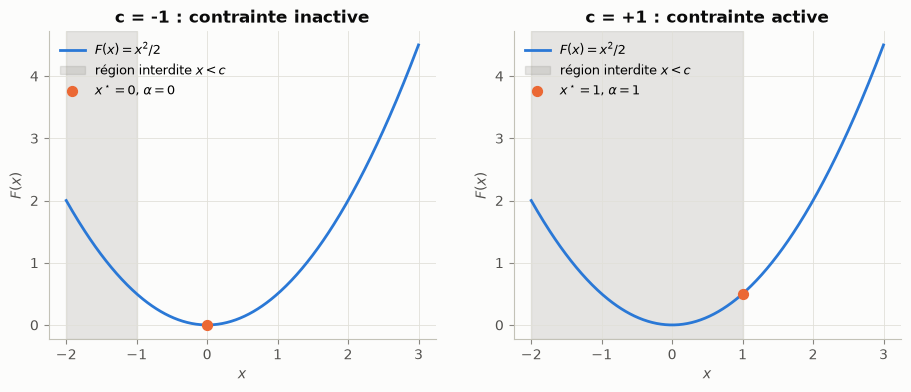

In [3]:
x = np.linspace(-2, 3, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c in zip(axes, [-1.0, 1.0]):
    ax.plot(x, 0.5 * x ** 2, color=BLUE, label=r"$F(x) = x^2/2$")
    ax.axvspan(-2, c, color=GRAY, alpha=0.2, label="région interdite $x < c$")
    xs = max(c, 0)
    ax.scatter([xs], [0.5 * xs ** 2], color=ORANGE, zorder=3, s=50,
               label=r"$x^\star = %.0f$, $\alpha = %.0f$" % (xs, max(c, 0)))
    ax.set_xlabel("$x$"); ax.set_ylabel("$F(x)$")
    ax.set_title("c = %+.0f : contrainte %s" % (c, "inactive" if c <= 0 else "active"))
    ax.legend(loc="upper left")
plt.show()

### 3.3 Conditions de Karush–Kuhn–Tucker (KKT)

Plus généralement, considérons le problème

$$\min_{x\in\mathbb{R}^n} F(x) \quad \text{sous}\quad g_i(x) \ge 0,\ i = 1, \dots, m,$$

avec $F$ **convexe** et les $g_i$ **affines** (c'est exactement notre cadre). Le Lagrangien
est $\mathcal{L}(x, \alpha) = F(x) - \sum_i \alpha_i g_i(x)$, avec $\alpha_i \ge 0$.

**Théorème (admis).** Sous ces hypothèses, $x^\star$ est solution si et seulement s'il
existe $\alpha^\star \in \mathbb{R}^m$ tel que :

1. *stationnarité* : $\nabla F(x^\star) = \sum_i \alpha^\star_i \nabla g_i(x^\star)$ ;
2. *admissibilité* : $g_i(x^\star) \ge 0$ ;
3. *positivité des multiplicateurs* : $\alpha^\star_i \ge 0$ ;
4. *complémentarité* : $\alpha^\star_i\, g_i(x^\star) = 0$ pour tout $i$.

Ce sont les conditions KKT. La condition 4 généralise l'exemple précédent : un
multiplicateur non nul signale une contrainte saturée.

### 3.4 Dualité

On définit la **fonction duale** $D(\alpha) = \min_x \mathcal{L}(x, \alpha)$ pour
$\alpha \ge 0$.

**Dualité faible.** Pour tout $x$ admissible et tout $\alpha \ge 0$, $D(\alpha) \le F(x)$.

*Preuve.* $D(\alpha) \le \mathcal{L}(x, \alpha) = F(x) - \sum_i \alpha_i g_i(x) \le F(x)$,
car chaque terme $\alpha_i g_i(x)$ est positif ($\alpha_i \ge 0$ et $g_i(x) \ge 0$). $\square$

**Dualité forte (admise).** Dans le cadre convexe à contraintes affines, si le problème a une
solution, $\max_{\alpha \ge 0} D(\alpha) = \min_{x \text{ admissible}} F(x)$ : on peut
résoudre le **problème dual** à la place du primal.

Vérifions-le sur l'exemple 1D avec $c = 1$ : $\min_x \mathcal{L} $ est atteint en $x = \alpha$,
donc $D(\alpha) = \tfrac12\alpha^2 - \alpha(\alpha - 1) = \alpha - \tfrac12\alpha^2$, maximal en
$\alpha = 1$ où il vaut $\tfrac12 = F(1)$.

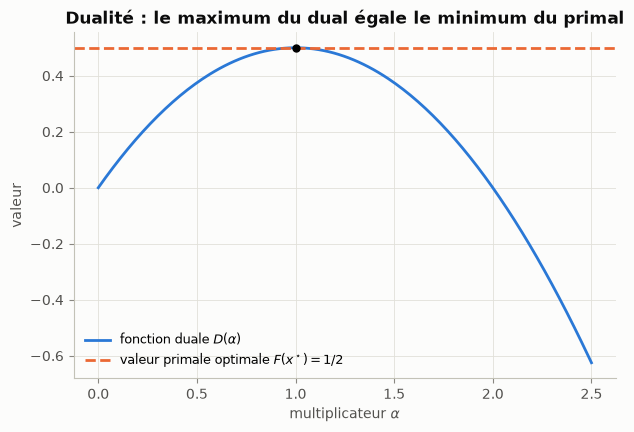

In [4]:
alpha = np.linspace(0, 2.5, 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(alpha, alpha - 0.5 * alpha ** 2, color=BLUE, label=r"fonction duale $D(\alpha)$")
ax.axhline(0.5, color=ORANGE, ls="--", label=r"valeur primale optimale $F(x^\star) = 1/2$")
ax.scatter([1], [0.5], color="k", zorder=3)
ax.set_xlabel(r"multiplicateur $\alpha$"); ax.set_ylabel("valeur")
ax.set_title("Dualité : le maximum du dual égale le minimum du primal")
ax.legend()
plt.show()

## 4. Le cas séparable : marge dure

Appliquons ces outils à $\min \tfrac12\|\beta\|^2$ sous $y_i(x_i^T\beta + \beta_0) \ge 1$.
Le Lagrangien est

$$\mathcal{L}(\beta, \beta_0, \alpha) = \tfrac12\|\beta\|^2 - \sum_{i=1}^N \alpha_i\left[y_i(x_i^T\beta + \beta_0) - 1\right],\qquad \alpha_i \ge 0.$$

**Stationnarité.** On dérive par rapport à $\beta$ (gradient) et à $\beta_0$ :

$$\nabla_\beta \mathcal{L} = \beta - \sum_i \alpha_i y_i x_i = 0 \;\Rightarrow\; \beta = \sum_i \alpha_i y_i x_i,
\qquad \frac{\partial \mathcal{L}}{\partial\beta_0} = -\sum_i \alpha_i y_i = 0.$$

**Problème dual.** On remplace $\beta$ par $\sum_i\alpha_i y_i x_i$ dans $\mathcal{L}$, en
utilisant $\sum_i \alpha_i y_i = 0$ (le terme en $\beta_0$ disparaît) :

$$\begin{aligned}
D(\alpha) &= \tfrac12 \Big\|\sum_i \alpha_i y_i x_i\Big\|^2 - \sum_i \alpha_i y_i x_i^T \sum_{i'} \alpha_{i'} y_{i'} x_{i'} + \sum_i \alpha_i \\
&= \sum_i \alpha_i - \tfrac12 \sum_{i}\sum_{i'} \alpha_i\alpha_{i'} y_i y_{i'}\, x_i^T x_{i'} .
\end{aligned}$$

On maximise $D$ sous $\alpha_i \ge 0$ et $\sum_i \alpha_i y_i = 0$.

**Complémentarité.** $\alpha_i [y_i(x_i^T\beta + \beta_0) - 1] = 0$ : seuls les points situés
**exactement sur le bord de la marge** ont $\alpha_i > 0$. Ce sont les **vecteurs de support** :
$\beta$ ne dépend que d'eux.

Résolvons numériquement le dual sur nos données séparables. Le module `esl.ch12_svm`
fournit `SVMClassifier` ; un coût $C$ très grand (voir section 5) reproduit la marge dure.